### Quantum teleportation

In [43]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

#### create a quantum circuit containing:
#### one quantum register of one qubit which we will put in the quantum state to be teleported
#### one quantum register of one qubit belonging to Alice
#### one quantum register of one qubit belonging to Bob: he will be the receiver of the teleported quantum state
#### two classical registers, each with one bit

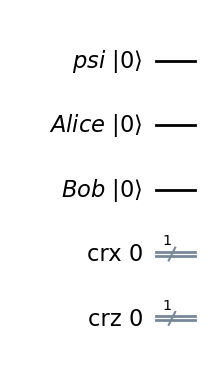

In [44]:
qr_psi = QuantumRegister(1, "psi")
qr_A = QuantumRegister(1, "Alice")
qr_B = QuantumRegister(1, "Bob")
crx = ClassicalRegister(1, "crx")
crz = ClassicalRegister(1, "crz")
qc = QuantumCircuit(qr_psi, qr_A, qr_B, crx, crz)
qc.draw('mpl', initial_state=True)

#### generate a random quantum state vector $\psi$

In [45]:
from qiskit import quantum_info as qi

In [46]:
psi = qi.random_statevector(2, seed = 27112025)
print(psi)

Statevector([0.57314058+0.41701601j, 0.54866201-0.44337063j],
            dims=(2,))


#### build a gate which can initialize a qubit initially in the $\lvert 0 \rangle$ state with the $\lvert \psi \rangle$ state

In [47]:
from qiskit.circuit.library import Initialize

In [48]:
psi_gate = Initialize(psi)

In [49]:
psi_gate.label = "init"

#### append this initializing gate to the circuit, on the "psi" register

In [50]:
qc.append(psi_gate, qr_psi)

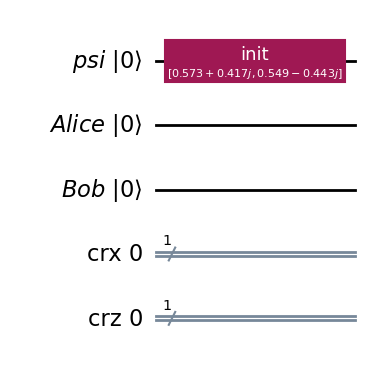

In [51]:
qc.draw('mpl', initial_state=True)

#### plot on the Bloch spheres the initial state of the three qubits

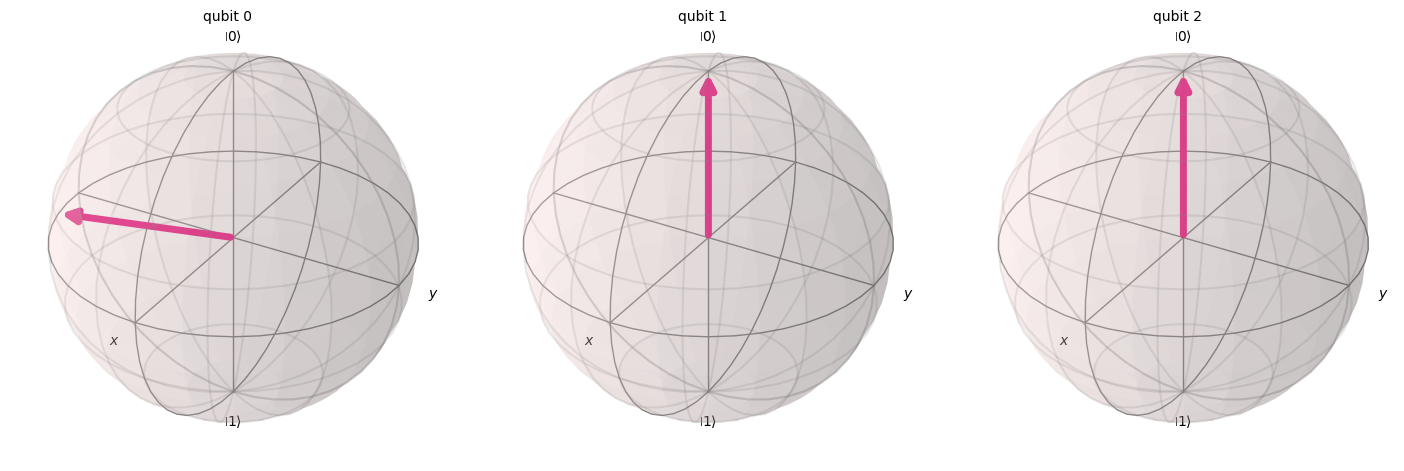

In [52]:
from qiskit.visualization import plot_bloch_multivector
psi_all = qi.Statevector(qc)
plot_bloch_multivector(psi_all)

In [53]:
qc.barrier()
qc.draw()

┌─────────────────────────────────────────┐ ░ 
  psi: ┤ init(0.57314+0.41702j,0.54866-0.44337j) ├─░─
       └─────────────────────────────────────────┘ ░ 
Alice: ────────────────────────────────────────────░─
                                                   ░ 
  Bob: ────────────────────────────────────────────░─
                                                   ░ 
crx: 1/══════════════════════════════════════════════
                                                     
crz: 1/══════════════════════════════════════════════

#### put the Bob qubit and the Alice qubit in maximum entanglement (Bell state);
#### at this stage we assume that Alice and Bob are in the same place (laboratory)
#### where the pair of entangled qubits is created

In [54]:
qc.h(qr_A)
qc.cx(qr_A, qr_B)
qc.draw()

┌─────────────────────────────────────────┐ ░           
  psi: ┤ init(0.57314+0.41702j,0.54866-0.44337j) ├─░───────────
       └─────────────────────────────────────────┘ ░ ┌───┐     
Alice: ────────────────────────────────────────────░─┤ H ├──■──
                                                   ░ └───┘┌─┴─┐
  Bob: ────────────────────────────────────────────░──────┤ X ├
                                                   ░      └───┘
crx: 1/════════════════════════════════════════════════════════
                                                               
crz: 1/════════════════════════════════════════════════════════

#### $\Rightarrow$ after doint this, Bob takes his qubit and goes away, while Alice
#### receives the $\lvert \psi \rangle$ state to be teleported

#### now (reverse) entangle the Alice qubit with the "psi" qubit

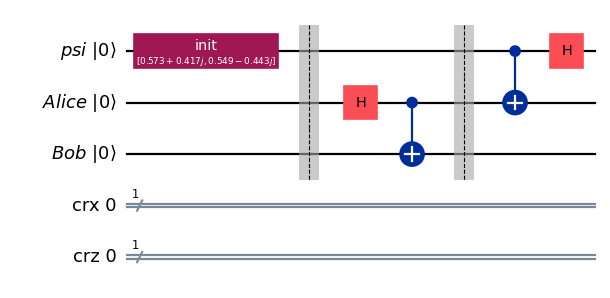

In [55]:
qc.barrier()
qc.cx(qr_psi, qr_A)
qc.h(qr_psi)
qc.draw('mpl', initial_state=True, scale = 0.8)

#### measure the "psi" qubit and the Alice qubit and send the results to Bob via the two classical channels "crx" and "crz"

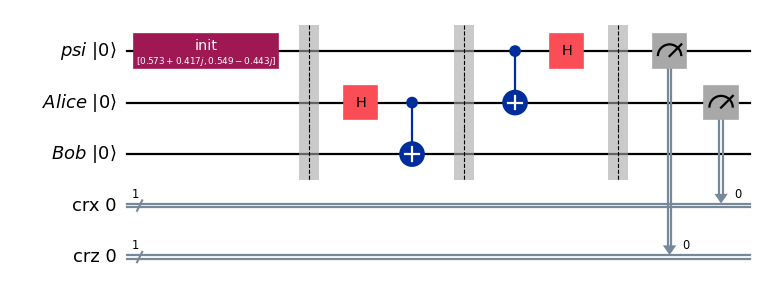

In [56]:
qc.barrier()
qc.measure(qr_psi, crz)
qc.measure(qr_A, crx)
qc.draw('mpl', initial_state=True, scale = 0.8)

#### acording to the received classical results of the measurements performed by Alice, 
#### Bob conditionally applies X or/and Z gates to his qubit (or none)

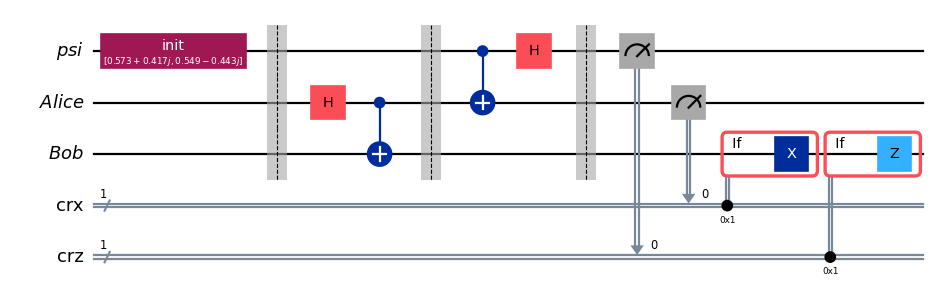

In [57]:
with qc.if_test((crx, 1)):
    qc.x(qr_B)
with qc.if_test((crz, 1)):
    qc.z(qr_B)
qc.draw('mpl', scale = 0.8)

#### do a state vector simulation

In [59]:
from qiskit_aer import Aer

backend = Aer.get_backend('statevector_simulator')

In [60]:
psi_f = backend.run(qc).result().get_statevector()
print(psi_f)

Statevector([ 0.        +0.j        , -0.        +0.j        ,
              0.        +0.j        ,  0.57314058+0.41701601j,
             -0.        +0.j        , -0.        +0.j        ,
             -0.        +0.j        ,  0.54866201-0.44337063j],
            dims=(2, 2, 2))


#### and plot the result on the Bloch sphere

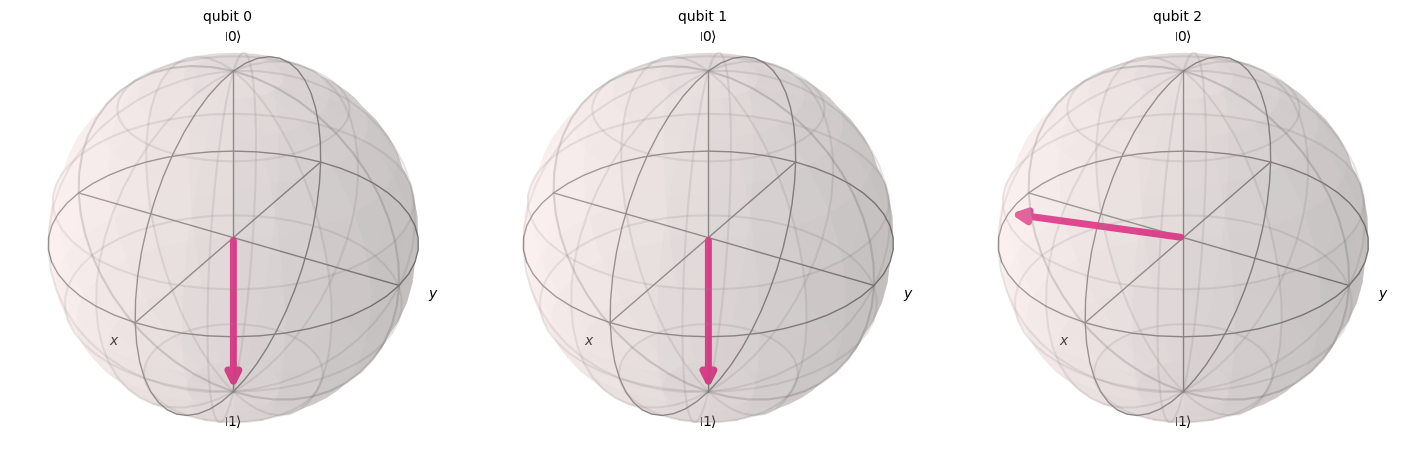

In [61]:
plot_bloch_multivector(psi_f)

#### $\Rightarrow$ the state $\psi$ initially on the first qubit is now on Bob's qubit

#### check this also using the reduced density matrix

In [63]:
from qiskit.visualization import array_to_latex

rho_f = qi.DensityMatrix(psi_f)
array_to_latex(rho_f)

<IPython.core.display.Latex object>

In [65]:
rho_f_B = qi.partial_trace(rho_f, [0, 1])
array_to_latex(rho_f_B)

<IPython.core.display.Latex object>

In [66]:
rho_f_B.purity()

np.complex128(0.9999999999999993+0j)